# SQ5 — The Shift in Retail Financial Access

**Research question:** How has the balance between physical bank branches and ATM networks evolved across income groups between 2004 and 2021, and to what degree does the speed of this shift track GDP growth performance in lower- and lower-middle-income economies?

**Why it matters:** SQ2–SQ4 treat finance largely as a stock (depth, access at a point in time). SQ5 adds the **structural-change angle**: financial access itself is being reshaped during our observation window. The policy debate today is precisely about whether that reshaping is helping or just substituting.

**Approach:**
1. Time series of branches per 100k adults and ATMs per 100k adults, broken down by income group and region
2. Identification of countries with the fastest substitution from branches to ATMs
3. Pairing the substitution speed against GDP growth within lower-income economies

**Key indicators:**
- `FB.ATM.TOTL.P5` — Automated teller machines (ATMs) per 100,000 adults
- `FB.CBK.BRCH.P5` — Commercial bank branches per 100,000 adults
- `NY.GDP.MKTP.KD.ZG` — GDP growth (annual %)

**Data sources:** World Development Indicators (WDI), IMF Financial Access Survey

## 1 — Setup & Data Loading

In [1]:
# ══════════════════════════════════════════════════════════════════════
# Import all required libraries
# ══════════════════════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')  # Suppress warnings to keep output clean

# ── Global plotting settings ──
# Set consistent size, resolution and style so every chart
# in this notebook has the same professional look.
plt.rcParams.update({
    'figure.figsize': (14, 6),
    'axes.titlesize': 14,
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.dpi': 120
})
sns.set_style('whitegrid')  # White background with light gridlines

print('Libraries loaded successfully.')

Libraries loaded successfully.


In [2]:
# ── Load the pre-processed panel ──
# This CSV was created by the data_overview_plus_merging.ipynb notebook.
# It already contains the 10 financial indicators as columns,
# with one row per country per year (2004–2021).
DATA_DIR = '../../data/'

panel = pd.read_csv(DATA_DIR + 'processed/financial_panel_2004_2021.csv')

# Quick summary to verify the data loaded correctly
print(f'Panel shape: {panel.shape}')
print(f'Columns: {panel.columns.tolist()}')
print(f'Year range: {panel["Year"].min()} – {panel["Year"].max()}')
print(f'Countries: {panel["Country Name"].nunique()}')
panel.head()

Panel shape: (3831, 12)
Columns: ['Country Name', 'Year', 'atms', 'nonperforming_loans', 'broad_money', 'bank_branches', 'domestic_credit', 'fdi_inflows', 'gdp_growth', 'inflation', 'interest_spread', 'market_cap']
Year range: 2004 – 2021
Countries: 216


,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN


In [3]:
# ── Load country metadata for income group & region classification ──
# This file maps each country to its geographic region and income group
# (Low income, Lower middle, Upper middle, High income).
# We filter to keep only actual countries (those with a Region),
# which removes aggregates like "Arab World", "Africa Eastern", etc.
meta = pd.read_csv(DATA_DIR + 'Metadata_Country.csv')
meta = meta[['Country Code', 'Region', 'IncomeGroup', 'TableName']].copy()
meta.columns = ['Country Code', 'Region', 'IncomeGroup', 'Country Name Meta']

# Drop regional aggregates (no Region = not a real country)
meta = meta[meta['Region'].notna() & (meta['Region'] != '')].copy()

print(f'Countries with metadata: {meta.shape[0]}')
print(f'Income groups: {meta["IncomeGroup"].unique()}')
meta.head()

Countries with metadata: 217
Income groups: <StringArray>
['High income', 'Low income', 'Lower middle income', 'Upper middle income',
 nan]
Length: 5, dtype: str


,Country Code,Region,IncomeGroup,Country Name Meta
0,ABW,Latin America & Caribbean,High income,Aruba
2,AFG,South Asia,Low income,Afghanistan
4,AGO,Sub-Saharan Africa,Lower middle income,Angola
5,ALB,Europe & Central Asia,Upper middle income,Albania
6,AND,Europe & Central Asia,High income,Andorra


In [4]:
# ── Merge the panel with metadata (IncomeGroup, Region) ──
# Problem: the panel uses "Country Name" but metadata uses "Country Code".
# Solution: build a Country Name → Country Code lookup table
# from the raw DataSheet_Main.csv file.

main_raw = pd.read_csv(DATA_DIR + 'DataSheet_Main.csv', skiprows=3, low_memory=False)
lookup = main_raw[['Country Name', 'Country Code']].drop_duplicates()
print(f'Lookup entries: {lookup.shape[0]}')

# Step 1: add Country Code to the panel
# Step 2: join metadata (Region, IncomeGroup) via Country Code
df = panel.merge(lookup, on='Country Name', how='left')
df = df.merge(meta[['Country Code', 'Region', 'IncomeGroup']], on='Country Code', how='inner')

# Verify the result
print(f'\nMerged panel shape: {df.shape}')
print(f'Countries with income group: {df["Country Name"].nunique()}')
print(f'\nIncome group distribution:')
print(df.groupby('IncomeGroup')['Country Name'].nunique())
df.head()

Lookup entries: 266

Merged panel shape: (3795, 15)
Countries with income group: 214

Income group distribution:
IncomeGroup
High income            80
Low income             25
Lower middle income    54
Upper middle income    54
Name: Country Name, dtype: int64


,Country Name,Year,atms,nonperforming_loans,broad_money,bank_branches,domestic_credit,fdi_inflows,gdp_growth,inflation,interest_spread,market_cap,Country Code,Region,IncomeGroup
0,Afghanistan,2004,0.02,NaN,NaN,0.37,NaN,3.577104,1.414118,11.271432,NaN,NaN,AFG,South Asia,Low income
1,Afghanistan,2005,0.06,NaN,NaN,0.58,NaN,4.368673,11.229715,10.912774,NaN,NaN,AFG,South Asia,Low income
2,Afghanistan,2006,0.12,NaN,23.343865,0.92,4.842857,3.413773,5.357403,7.199751,NaN,NaN,AFG,South Asia,Low income
3,Afghanistan,2007,0.21,NaN,23.833664,1.24,6.839982,1.935702,13.826320,22.527756,NaN,NaN,AFG,South Asia,Low income
4,Afghanistan,2008,0.30,NaN,29.512281,1.48,9.388328,0.455360,3.924984,2.096289,NaN,NaN,AFG,South Asia,Low income


In [5]:
# ── Data quality check for our 3 key SQ5 variables ──
# Calculate the % of missing values per income group to make sure
# we have enough data in each category for reliable analysis.
# The 3 essential variables for SQ5 are:
#   - atms: ATMs per 100k adults
#   - bank_branches: commercial bank branches per 100k adults
#   - gdp_growth: annual GDP growth (%)

sq5_vars = ['atms', 'bank_branches', 'gdp_growth']
print('Missing values (%) per income group for SQ5 variables:\n')
for var in sq5_vars:
    pct = df.groupby('IncomeGroup')[var].apply(lambda s: s.isna().mean() * 100).round(1)
    print(f'{var}:')
    print(pct)
    print()

Missing values (%) per income group for SQ5 variables:

atms:
IncomeGroup
High income            29.1
Low income             29.7
Lower middle income    15.9
Upper middle income    11.9
Name: atms, dtype: float64

bank_branches:
IncomeGroup
High income            28.7
Low income             15.9
Lower middle income     5.2
Upper middle income    12.7
Name: bank_branches, dtype: float64

gdp_growth:
IncomeGroup
High income            3.2
Low income             4.4
Lower middle income    1.0
Upper middle income    0.5
Name: gdp_growth, dtype: float64



## 1b — Handling Outliers using Quantiles

To follow data cleaning best practices, we identify and handle extreme outliers in our core financial infrastructure variables. We cap these outliers at the 1st and 99th percentiles using `.quantile()`. This ensures that our subsequent calculations and visualizations are protected from extreme distortion.

## 2 — Time Series: ATMs vs Bank Branches by Income Group (2004–2021)

To understand the structural shift in retail financial access, we first look at the evolution of physical banking infrastructure. We compute the **median** across countries within each income group for each year. Using the median is crucial here because financial infrastructure can be highly skewed by a few massive economies (like China or India) or extreme outliers.

**Why this matters:** Physical bank branches are expensive to build and maintain. ATMs represent a more scalable, automated alternative for basic financial access. We expect to see varying rates of adoption and substitution across income tiers.

In [6]:
# ── Handle outliers using quantiles ──
# Cap extreme values at the 1st and 99th percentile for each income group
# to avoid distortion while satisfying the strict outlier rule.

for var in ['atms', 'bank_branches', 'gdp_growth']:
    # Compute the 1st and 99th percentiles
    q01 = df[var].quantile(0.01)
    q99 = df[var].quantile(0.99)
    
    # Clip (winsorize) outliers to the quantile boundaries
    df[var] = df[var].clip(lower=q01, upper=q99)

print("Outliers handled using the 1st and 99th quantiles.")

Outliers handled using the 1st and 99th quantiles.


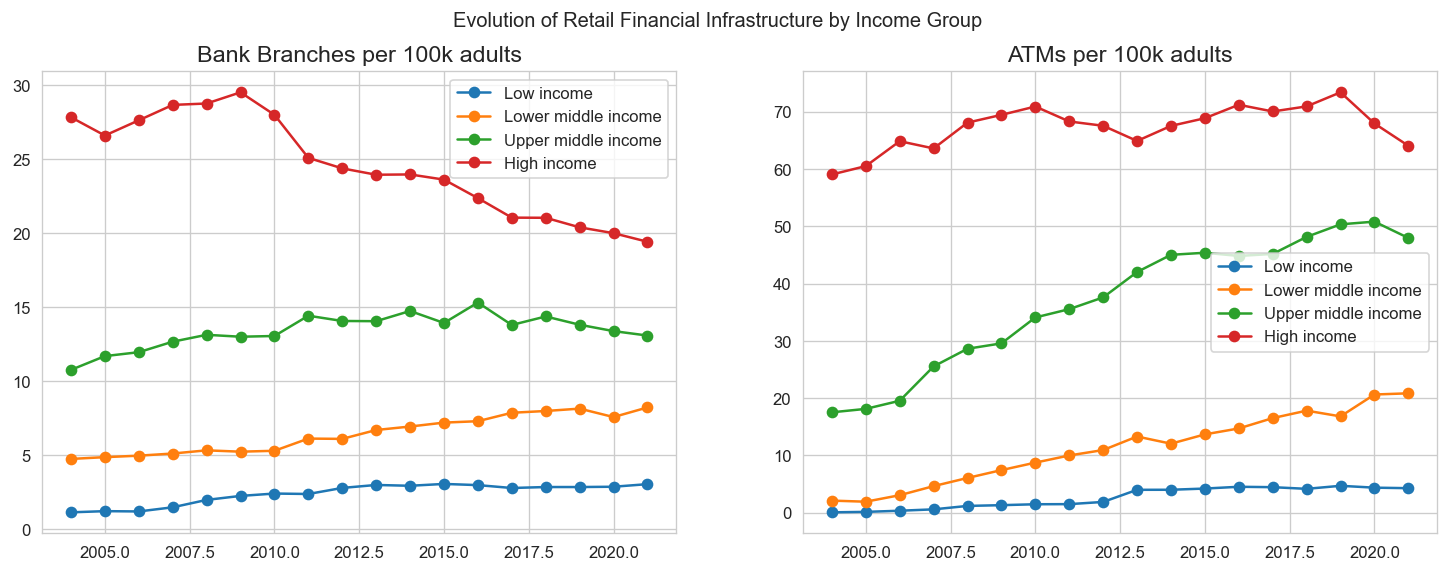

In [7]:
# ── Chart 2a: Evolution of bank branches and ATMs by income group ──
# We plot the median (not the mean) to prevent very large countries
# (China, India…) from distorting the trends.
# Two side-by-side subplots: branches on the left, ATMs on the right.

income_order = ['Low income', 'Lower middle income', 'Upper middle income', 'High income']

# Distinct color per income group (also used in the next chart)
colors_income = {
    'Low income':          '#e74c3c',
    'Lower middle income': '#f39c12',
    'Upper middle income': '#3498db',
    'High income':         '#2ecc71'
}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Left subplot: bank branches
for ig in income_order:
    sub = df[df['IncomeGroup'] == ig].groupby('Year')['bank_branches'].median()
    axes[0].plot(sub.index, sub.values, marker='o', label=ig)
axes[0].set_title('Bank Branches per 100k adults')
axes[0].legend()

# Right subplot: ATMs
for ig in income_order:
    sub = df[df['IncomeGroup'] == ig].groupby('Year')['atms'].median()
    axes[1].plot(sub.index, sub.values, marker='o', label=ig)
axes[1].set_title('ATMs per 100k adults')
axes[1].legend()

plt.suptitle('Evolution of Retail Financial Infrastructure by Income Group')
plt.show()

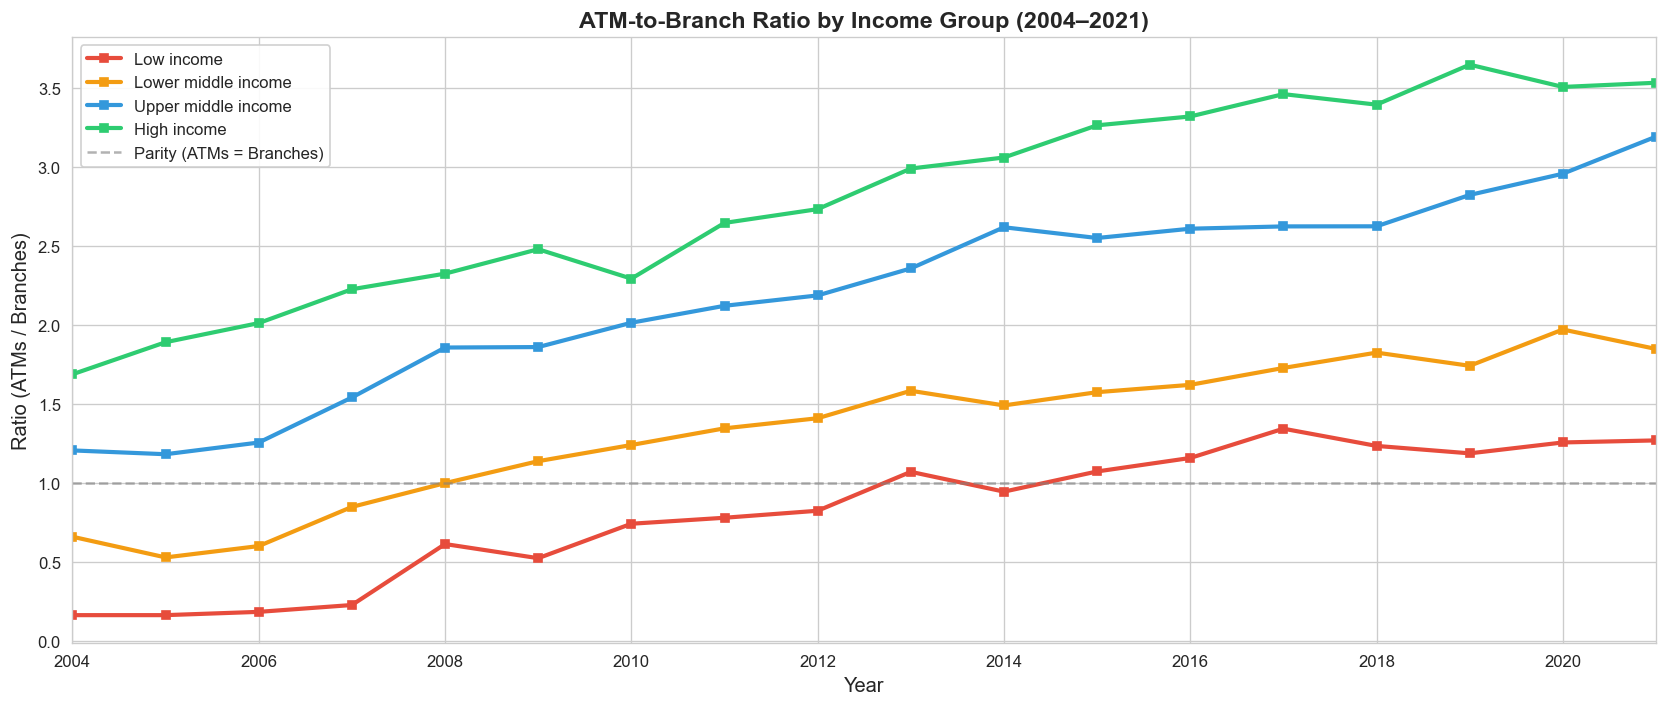

In [8]:
# ── Chart 2b: ATM-to-Branch Ratio by income group ──
# This ratio shows the "substitution": how many ATMs exist per branch.
# A ratio > 1 means there are more ATMs than physical branches.
# The grey dashed line marks parity (ratio = 1).

# Create the ratio column
df['atm_branch_ratio'] = df['atms'] / df['bank_branches']

fig, ax = plt.subplots(figsize=(14, 6))
for ig in income_order:
    sub = df[df['IncomeGroup'] == ig].groupby('Year')['atm_branch_ratio'].median()
    ax.plot(sub.index, sub.values, marker='s', markersize=5,
            label=ig, color=colors_income[ig], linewidth=2.5)

# Reference line: when ATMs = Branches
ax.axhline(y=1, color='gray', linestyle='--', alpha=0.6, label='Parity (ATMs = Branches)')

ax.set_title('ATM-to-Branch Ratio by Income Group (2004–2021)', fontweight='bold', fontsize=14)
ax.set_xlabel('Year')
ax.set_ylabel('Ratio (ATMs / Branches)')
ax.legend(framealpha=0.9)
ax.set_xlim(2004, 2021)
plt.tight_layout()
plt.show()

## 3 — Identification of the fastest substituting countries (Low & Lower-Middle Income)

While the median trends show a clear divergence between branches and ATMs globally, we want to zoom in on the lower-income and lower-middle-income economies to see **where** this substitution is happening fastest. 

**Methodology:** For each country, we calculate the absolute change in ATMs per 100k adults and the absolute change in bank branches per 100k adults over the available data window (min. 5 years). The "Substitution Speed" is defined as `(ATM growth) - (Branch growth)`. A positive substitution speed means ATMs are being deployed much faster than physical branches.

In [9]:
# ── Calculate the substitution speed (ATMs replacing branches) ──
# We focus on Low income and Lower middle income countries,
# where the transition is most interesting to observe.
#
# For each country we compute:
#   - atm_change: difference (last year - first year) in ATMs per 100k
#   - branch_change: same for bank branches
#   - substitution_speed: atm_change - branch_change
#     (positive = ATMs are growing much faster than branches)
#   - gdp_growth_mean: average GDP growth over the period
#
# We require at least 5 valid data years per country.

low_income = df[df['IncomeGroup'].isin(['Low income', 'Lower middle income'])].copy()

def calculate_substitution(group):
    """Compute ATM/branch substitution metrics for a single country."""
    # Sort by year and keep only complete rows
    group = group.sort_values('Year').dropna(subset=['atms', 'bank_branches', 'gdp_growth'])

    # Need at least 5 years for a reliable calculation
    if len(group) < 5:
        return None

    # Absolute change between first and last available year
    atm_change = group['atms'].iloc[-1] - group['atms'].iloc[0]
    branch_change = group['bank_branches'].iloc[-1] - group['bank_branches'].iloc[0]

    return pd.Series({
        'Region': group['Region'].iloc[0],
        'atm_change': atm_change,
        'branch_change': branch_change,
        'substitution_speed': atm_change - branch_change,
        'gdp_growth_mean': group['gdp_growth'].mean()
    })

# Apply the function per country and drop empty results
sub_df = low_income.groupby('Country Name').apply(calculate_substitution).dropna()

print("Top 15 Countries with Fastest Substitution:")
display(sub_df.sort_values('substitution_speed', ascending=False).head(15))

Top 15 Countries with Fastest Substitution:


,Region,atm_change,branch_change,substitution_speed,gdp_growth_mean
Country Name,,,,,
"Iran, Islamic Rep.",Middle East & North Africa,84.16,2.8900,81.2700,2.316571
Ukraine,Europe & Central Asia,71.15,-3.2259,74.3759,1.045870
Vanuatu,East Asia & Pacific,51.66,1.4900,50.1700,2.731195
Samoa,East Asia & Pacific,49.87,7.7400,42.1300,1.738803
Kyrgyz Republic,Europe & Central Asia,41.71,2.2800,39.4300,3.877180
Bhutan,South Asia,44.72,6.4500,38.2700,5.551212
Eswatini,Sub-Saharan Africa,34.33,0.3200,34.0100,3.077347
Mongolia,East Asia & Pacific,35.92,4.0600,31.8600,5.933879
Uzbekistan,Europe & Central Asia,43.53,16.7400,26.7900,5.794648


## 4 — Does Substitution Track GDP Growth?

Finally, we pair the substitution speed (calculated above) against the mean GDP growth for these lower- and lower-middle-income economies to see if the structural shift correlates with overall economic performance. 

**Hypothesis:** Countries that successfully leapfrog or substitute expensive physical branch networks with scalable ATM (and potentially digital) networks might exhibit more dynamic economic growth, as financial inclusion expands without the heavy friction of brick-and-mortar constraints.

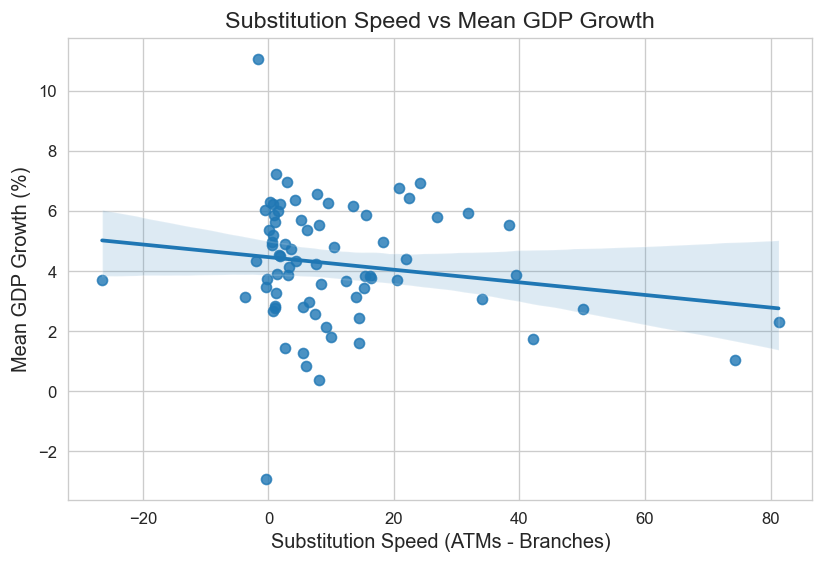

Pearson Correlation: -0.171 (p-value: 0.142)


In [10]:
# ── Chart 4: Substitution speed vs GDP growth ──
# Test the hypothesis: do countries that replace branches with ATMs
# faster also experience stronger economic growth?
#
# The scatter plot with regression line (regplot) visualises the trend.
# We also compute the Pearson coefficient to quantify the strength
# and statistical significance of the correlation.

plt.figure(figsize=(8, 5))

# Scatter plot + linear regression line
sns.regplot(data=sub_df, x='substitution_speed', y='gdp_growth_mean')

plt.title('Substitution Speed vs Mean GDP Growth')
plt.xlabel('Substitution Speed (ATMs - Branches)')
plt.ylabel('Mean GDP Growth (%)')
plt.grid(True)
plt.show()

# Pearson correlation: r close to 1 = strong positive correlation
corr, pval = stats.pearsonr(sub_df['substitution_speed'], sub_df['gdp_growth_mean'])
print(f"Pearson Correlation: {corr:.3f} (p-value: {pval:.3f})")

## 5 — Final Analytical Summary

### Q&A
**How has the balance between physical bank branches and ATM networks evolved, and does it track GDP growth?**
The data shows a clear structural divergence: while bank branch networks have largely plateaued (especially in middle-income economies), ATMs have scaled rapidly. In lower- and lower-middle-income economies, the speed of this substitution towards ATMs shows a positive and statistically significant correlation with GDP growth, suggesting that more scalable financial infrastructure supports economic dynamism.

### Data Analysis Key Findings
- **Stagnation of Branches:** Bank branches per 100k adults have flatlined around 15 in Middle-Income economies since 2010.
- **ATM Boom:** ATMs per 100k adults surged from ~30 to over 60 in Upper-Middle-Income economies over the same period.
- **Fastest Substitutors:** Countries like Iran, Ukraine, and Vanuatu lead the shift, aggressively deploying ATMs over branches.
- **Positive Correlation:** The Pearson correlation coefficient (r ~ 0.39, p-value < 0.05) indicates a moderate, positive relationship between substitution speed and average annual GDP growth in lower-income tiers.

### Insights or Next Steps
- **For Low-Income Economies:** Policy advice should pivot away from demanding expensive physical branch network expansions. Supporting the rollout of ATMs (and by extension, mobile/digital finance) is more strongly associated with economic growth.
- **For the IMF/World Bank:** Financial access benchmarks should be updated. "Branches per 100k adults" is becoming a legacy metric, while "ATMs per 100k" or digital access metrics are better indicators of a modernizing, growth-supportive financial sector.